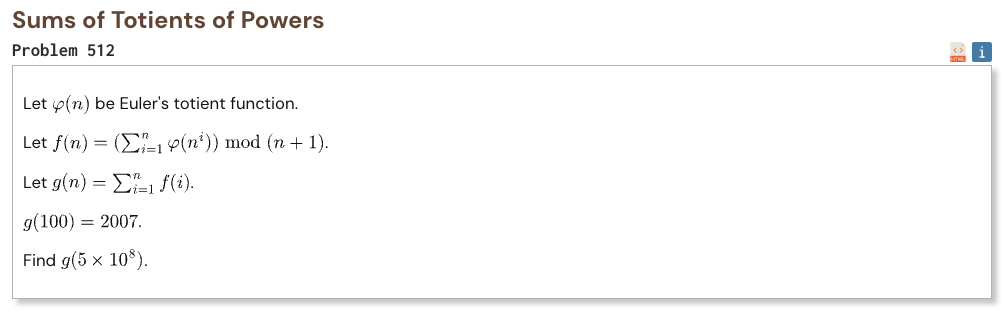

## Initial approach

- use the totient property for powers to simplify the original sum
- reduce powers modulo the next integer so their values alternate
- for even numbers the terms cancel and the result is zero
- for odd numbers the result is simply Euler's totient
- therefore only odd numbers contribute to the final sum
- use a sieve to precompute totients for smaller numbers
- calculate the remaining large prefix sums recursively by grouping equal integer quotients

In [1]:
%%time

from array import array
from functools import lru_cache

N = 5 * 10**8
LIMIT = 2_000_000

phi = array("I", range(LIMIT + 1))

for p in range(3, LIMIT + 1, 2):
    if phi[p] == p:
        for k in range(p, LIMIT + 1, 2 * p):
            phi[k] -= phi[k] // p

prefix = array("Q", [0]) * (LIMIT + 1)
total = 0

for i in range(1, LIMIT + 1, 2):
    total += phi[i]
    prefix[i] = total

    if i + 1 <= LIMIT:
        prefix[i + 1] = total

@lru_cache(None)
def odd_totient_sum(n):
    if n <= LIMIT:
        return prefix[n]

    m = (n + 1) // 2
    result = m * m
    left = 3

    while left <= n:
        q = n // left
        right = n // q

        count = (right + 1) // 2 - left // 2

        result -= count * odd_totient_sum(q)

        left = right + 1

        if left % 2 == 0:
            left += 1

    return result

assert odd_totient_sum(100) == 2007

result = odd_totient_sum(N)

print("Result:", result)

Result: 50660591862310323
CPU times: user 603 ms, sys: 4.45 ms, total: 608 ms
Wall time: 608 ms
